In [36]:
# import data sets 
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np


dataset_1 = np.loadtxt('datafile-exp.txt')
dataset_2 = np.loadtxt('datafile-expgaus.txt')


print(dataset_1)
print(dataset_2)

[1.0323898  6.62226715 2.89684053 ... 1.11462491 0.53856421 1.02922886]
[0.97160028 0.46505173 2.24309867 ... 5.25881333 5.53710739 5.31947016]


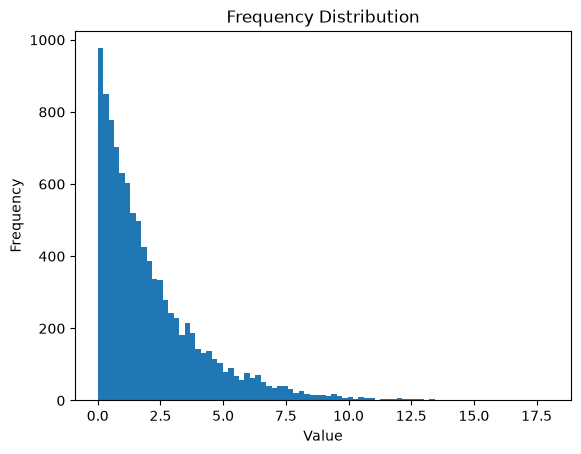

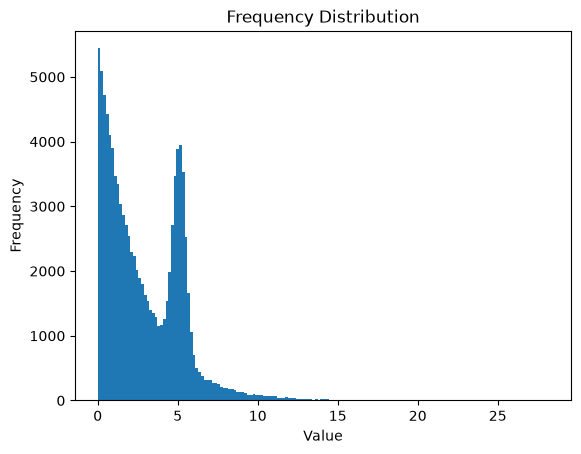

In [40]:
# plot data set 1 and data set 2 

plt.hist(dataset_1, bins='auto')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Frequency Distribution')
plt.show()

plt.hist(dataset_2, bins='auto')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Frequency Distribution')
plt.show()

In [50]:
from iminuit import cost, Minuit
import scipy.stats


def exp_pdf(x, scale):
    return scipy.stats.expon.pdf(x, loc=0, scale=scale)

# Define an unbinned negative log-likelihood
cost_exp = cost.UnbinnedNLL(dataset_1, exp_pdf)

# Initial estimate: for an exponential distribution, the mean is the scale parameter
scale0 = np.mean(dataset_1)

# Run the fit
m_exp = Minuit(cost_exp, scale0)
m_exp.migrad()
m_exp.hesse()

# Print out results
print(m_exp)
print('Fitted scale =', m_exp.values['scale'])

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 3.532e+04                  │              Nfcn = 20               │
│ EDM = 2.46e-17 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬─────

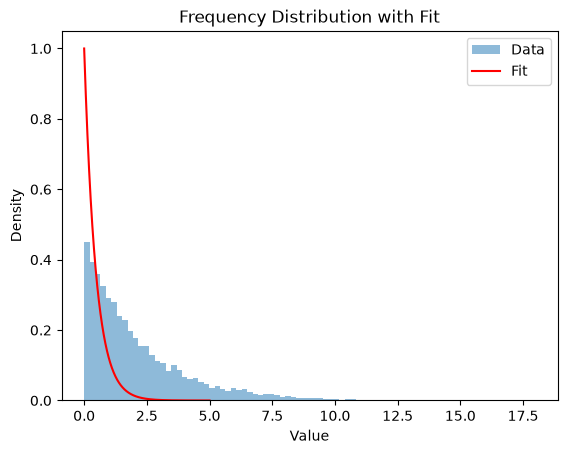

In [ ]:
# plot the data set with the fit overlayed

x_fit1 = np.linspace(0, np.max(dataset_1), 1000)
y_fit2 = scipy.stats.expon.pdf(x_fit1, loc=0, scale=m_exp.values['scale'])

plt.hist(dataset_1, bins='auto', density=True, alpha=0.5, label='Data')
plt.plot(x_fit1, y_fit2, 'r-', label='Fit')
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Frequency Distribution with Fit')
plt.legend()
plt.show()